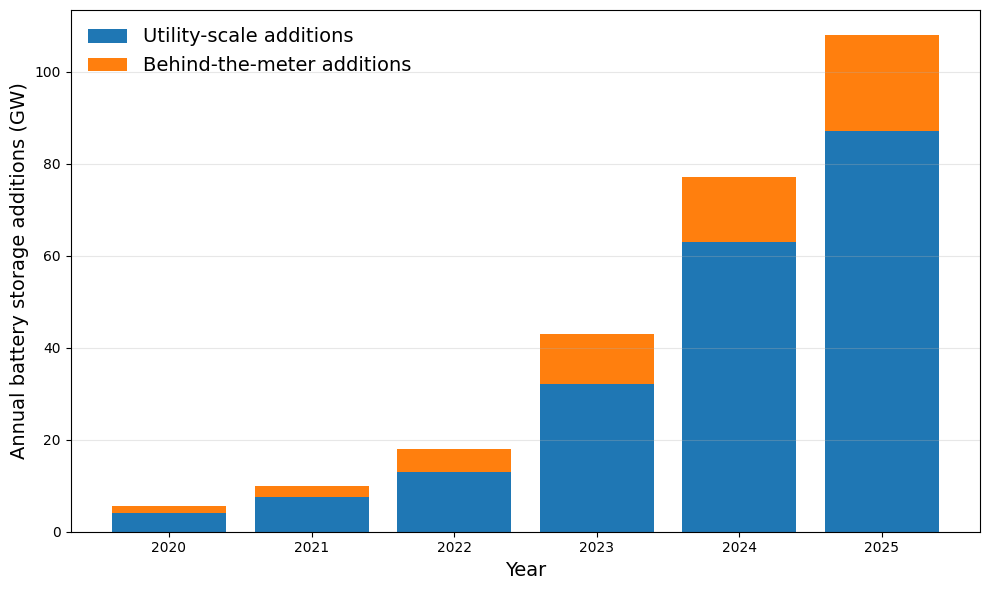

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Global battery storage additions, approximate GW values
# Source: IEA Global Energy Review 2026
# 2025 total = 108 GW reported directly by IEA.
# Earlier values are approximate/digitized from the IEA chart.
# ---------------------------------------------------------

data = pd.DataFrame({
    "year": [2020, 2021, 2022, 2023, 2024, 2025],
    "utility_scale_gw": [4.0, 7.5, 13.0, 32.0, 63.0, 87.0],
    "behind_meter_gw": [1.5, 2.5, 5.0, 11.0, 14.0, 21.0]
})

data["total_additions_gw"] = data["utility_scale_gw"] + data["behind_meter_gw"]

# Approximate cumulative installed capacity.
# Back-calculated so that 2025 installed capacity is about 11x 2021,
# consistent with IEA's statement.
# baseline_2019_gw = 9.2
# data["cumulative_installed_gw"] = baseline_2019_gw + data["total_additions_gw"].cumsum()

# ---------------------------------------------------------
# Plot
# ---------------------------------------------------------

fig, ax1 = plt.subplots(figsize=(10, 6))

# Stacked annual additions
ax1.bar(
    data["year"],
    data["utility_scale_gw"],
    label="Utility-scale additions"
)

ax1.bar(
    data["year"],
    data["behind_meter_gw"],
    bottom=data["utility_scale_gw"],
    label="Behind-the-meter additions"
)

ax1.set_xlabel("Year", fontsize=14)
ax1.set_ylabel("Annual battery storage additions (GW)", fontsize=14)
ax1.grid(axis="y", alpha=0.3)

# Cumulative installed capacity line on secondary axis
# ax2 = ax1.twinx()

# ax2.plot(
#     data["year"],
#     data["cumulative_installed_gw"],
#     marker="o",
#     linewidth=2.5,
#     label="Approx. cumulative installed capacity"
# )

# ax2.set_ylabel("Approx. cumulative installed capacity (GW)")

# Title and annotations
# plt.title(
#     "Global Growth of Battery Storage Capacity",
#     fontsize=14,
#     weight="bold"
# )

# ax1.annotate(
#     "Battery additions accelerate rapidly\nafter 2021",
#     xy=(2023, 43),
#     xytext=(2020.5, 85),
#     arrowprops=dict(arrowstyle="->", linewidth=1),
#     fontsize=10
# )

# ax2.annotate(
#     "IEA: 108 GW added in 2025",
#     xy=(2025, data.loc[data["year"] == 2025, "cumulative_installed_gw"].iloc[0]),
#     xytext=(2021.8, 240),
#     arrowprops=dict(arrowstyle="->", linewidth=1),
#     fontsize=10
# )

# Combine legends from both axes
handles1, labels1 = ax1.get_legend_handles_labels()
# handles2, labels2 = ax2.get_legend_handles_labels() + handles2  + labels2

ax1.legend(
    handles1 ,
    labels1,
    frameon=False,
    loc="upper left", fontsize= 14
)

plt.tight_layout()
plt.show()